In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)
print("Torch:", torch.__version__)

Device: cuda
Torch: 2.9.1+cu130


In [2]:
DATA_ROOT = "./data"
MAX_TRAIN_IMAGES = None   # Example: 4000 for a quick dry run; None = full training data
MAX_TEST_IMAGES = None    # Example: 1000 for a quick dry run; None = full test data
VAL_FRACTION = 0.10
BATCH_SIZE = 128
NUM_WORKERS = 0
IMAGE_SIZE = 32

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)

print("Raw CIFAR-10:", len(cifar_train), "train,", len(cifar_test), "test")
print("Classes:", cifar_train.classes)

# Stratify by CIFAR-10 object category before assigning watermark labels.
def stratified_indices(targets, selected_count=None, seed=42):
    targets = np.asarray(targets)
    rng = np.random.default_rng(seed)
    classes = np.unique(targets)
    if selected_count is None:
        selected_count = len(targets)
    if selected_count % (2 * len(classes)) != 0:
        raise ValueError("For balanced per-category watermark labels, selected_count must be divisible by 20.")
    per_class = selected_count // len(classes)
    indices = np.concatenate([
        rng.choice(np.where(targets == cls)[0], size=per_class, replace=False)
        for cls in classes
    ])
    return rng.permutation(indices)

all_train_indices = stratified_indices(cifar_train.targets, MAX_TRAIN_IMAGES, seed=SEED)
test_indices = stratified_indices(cifar_test.targets, MAX_TEST_IMAGES, seed=SEED + 1)

# Split within CIFAR object classes, so both train and validation stay stratified.
rng = np.random.default_rng(SEED + 2)
train_list, val_list = [], []
train_targets = np.asarray(cifar_train.targets)
for cls in np.unique(train_targets):
    class_indices = all_train_indices[train_targets[all_train_indices] == cls].copy()
    rng.shuffle(class_indices)
    n_val = round(len(class_indices) * VAL_FRACTION)
    if n_val % 2:  # keep watermark labels balanced within each CIFAR class
        n_val += 1
    val_list.extend(class_indices[:n_val].tolist())
    train_list.extend(class_indices[n_val:].tolist())
train_indices = rng.permutation(np.array(train_list, dtype=int))
val_indices = rng.permutation(np.array(val_list, dtype=int))

print(f"Unique originals: train={len(train_indices):,}; val={len(val_indices):,}; test={len(test_indices):,}")
assert not set(train_indices).intersection(val_indices)

c:\Users\TangyKiwi\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Raw CIFAR-10: 50000 train, 10000 test
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Unique originals: train=45,000; val=5,000; test=10,000


In [3]:
WATERMARK_STRENGTH = 0.02  # Main parameter: try 0.005, 0.01, 0.02, 0.05
WATERMARK_SEED = 2026
assert 0 <= WATERMARK_STRENGTH <= 1

pattern_generator = torch.Generator().manual_seed(WATERMARK_SEED)
watermark_pattern = (
    torch.randint(0, 2, (3, 32, 32), generator=pattern_generator, dtype=torch.int64)
    .float().mul(2).sub(1)
)

def add_watermark(image, strength=WATERMARK_STRENGTH, pattern=watermark_pattern):
    """Image: float Tensor [3,32,32] in [0,1]; returns watermarked image in [0,1]."""
    if image.shape != pattern.shape:
        raise ValueError(f"Expected image shape {tuple(pattern.shape)}, got {tuple(image.shape)}")
    return torch.clamp(image + float(strength) * pattern.to(image.device), 0, 1)

print("Watermark pattern shape:", tuple(watermark_pattern.shape))
print("Watermark strength:", WATERMARK_STRENGTH)

Watermark pattern shape: (3, 32, 32)
Watermark strength: 0.02


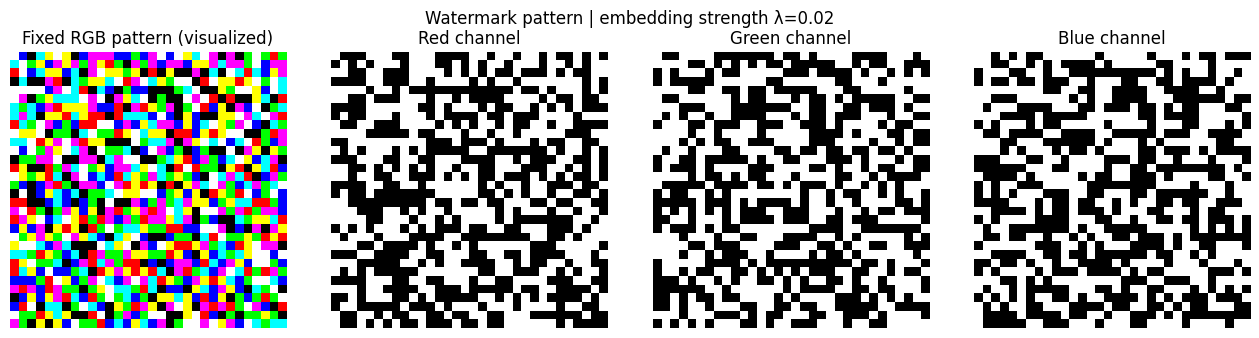

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
pattern_rgb = watermark_pattern.permute(1, 2, 0).numpy()
axes[0].imshow((pattern_rgb + 1) / 2)
axes[0].set_title("Fixed RGB pattern (visualized)")
for c, label in enumerate(["Red channel", "Green channel", "Blue channel"]):
    axes[c + 1].imshow(watermark_pattern[c], cmap="gray", vmin=-1, vmax=1)
    axes[c + 1].set_title(label)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"Watermark pattern | embedding strength λ={WATERMARK_STRENGTH}")
plt.tight_layout()
plt.show()

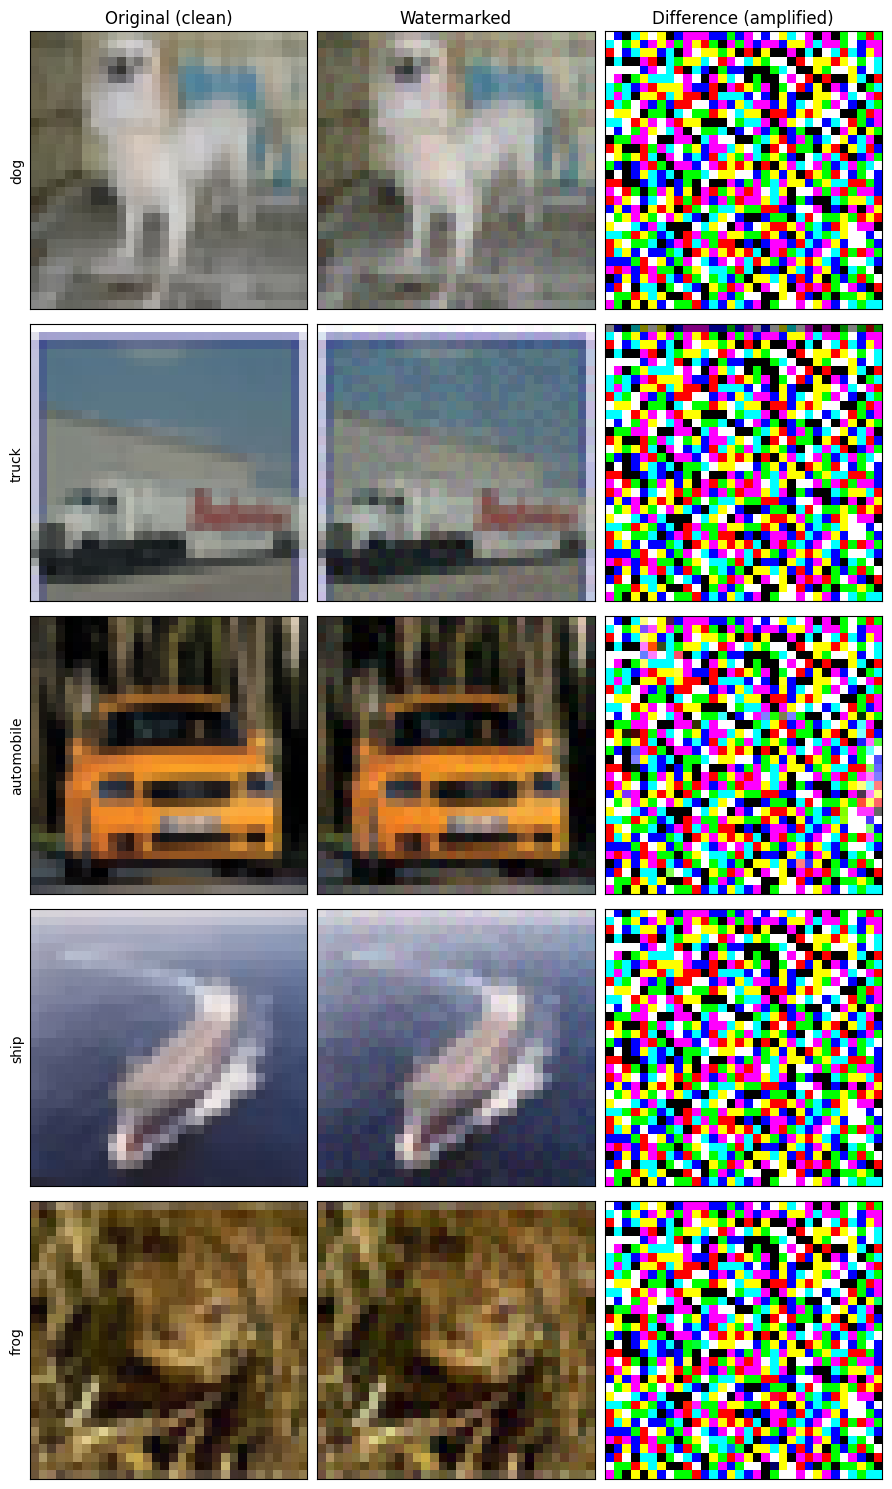

Example average MSE: 0.00039616
Example average PSNR: 34.02 dB


In [5]:
to_tensor = transforms.ToTensor()
examples = [cifar_train[int(i)] for i in train_indices[:5]]
fig, axes = plt.subplots(len(examples), 3, figsize=(9, 3 * len(examples)))
for row, (pil_img, object_label) in enumerate(examples):
    clean = to_tensor(pil_img)
    marked = add_watermark(clean)
    diff = marked - clean
    axes[row, 0].imshow(clean.permute(1, 2, 0))
    axes[row, 1].imshow(marked.permute(1, 2, 0))
    # Amplified difference is ONLY for visualization; not the actual pixel strength.
    axes[row, 2].imshow(torch.clamp((diff / max(WATERMARK_STRENGTH, 1e-8) + 1) / 2, 0, 1).permute(1, 2, 0))
    axes[row, 0].set_ylabel(cifar_train.classes[object_label])
for ax, label in zip(axes[0], ["Original (clean)", "Watermarked", "Difference (amplified)"]):
    ax.set_title(label)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

# Image-quality baseline on examples, using unnormalized pixel tensors in [0,1].
mse_values = [torch.mean((add_watermark(to_tensor(im)) - to_tensor(im)) ** 2).item()
              for im, _ in examples]
psnr_values = [float("inf") if mse == 0 else 10 * np.log10(1.0 / mse) for mse in mse_values]
print(f"Example average MSE: {np.mean(mse_values):.8f}")
print(f"Example average PSNR: {np.mean(psnr_values):.2f} dB")

In [6]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Inputs are PIL originals; watermark is injected before resizing and normalization.
class WatermarkCIFAR10(Dataset):
    def __init__(self, cifar_dataset, indices, strength=WATERMARK_STRENGTH,
                 pattern=watermark_pattern, seed=42, image_size=32):
        self.base = cifar_dataset
        self.indices = np.asarray(indices, dtype=int)
        self.strength = strength
        self.pattern = pattern
        self.image_size = image_size
        self.labels = np.zeros(len(self.indices), dtype=np.int64)
        object_labels = np.asarray(self.base.targets)[self.indices]
        rng = np.random.default_rng(seed)
        for cls in np.unique(object_labels):
            positions = np.flatnonzero(object_labels == cls)
            if len(positions) % 2:
                raise ValueError("Each source class must have even count for a 50/50 label split")
            rng.shuffle(positions)
            self.labels[positions[:len(positions) // 2]] = 1

        self.resize = transforms.Resize((image_size, image_size), antialias=True)
        self.normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])

        # Load directly from CIFAR-10's NumPy data
        image = self.base.data[idx]

        # HWC uint8 -> CHW float32 in [0, 1]
        x = (
            torch.from_numpy(image)
            .permute(2, 0, 1)
            .float()
            .div_(255.0)
        )

        y = int(self.labels[i])

        if y == 1:
            x = add_watermark(
                x,
                strength=self.strength,
                pattern=self.pattern
            )

        # Only resize when necessary
        if self.image_size != 32:
            x = self.resize(x)

        x = self.normalize(x)

        return x, y

trainset = WatermarkCIFAR10(cifar_train, train_indices, seed=SEED + 10)
valset = WatermarkCIFAR10(cifar_train, val_indices, seed=SEED + 11)
testset = WatermarkCIFAR10(cifar_test, test_indices, seed=SEED + 12)

trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True,
                         num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
valloader = DataLoader(valset, batch_size=BATCH_SIZE, shuffle=False,
                       num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")

summary = pd.DataFrame([
    {"partition": name, "unwatermarked": int(np.sum(ds.labels == 0)),
     "watermarked": int(np.sum(ds.labels == 1)), "total": len(ds)}
    for name, ds in [("train", trainset), ("validation", valset), ("test", testset)]
])
display(summary)
assert all((row.unwatermarked == row.watermarked) for row in summary.itertuples())

,partition,unwatermarked,watermarked,total
0,train,22500,22500,45000
1,validation,2500,2500,5000
2,test,5000,5000,10000


In [7]:
WEIGHTS = models.ResNet50_Weights.IMAGENET1K_V2
model = models.resnet50(weights=WEIGHTS)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
LEARNING_RATE = 0.001  # From PA Part II
MOMENTUM = 0.9         # From PA Part II
MAX_EPOCHS = 15        # From PA Part II
TOLERANCE = 1e-6       # PA Part II early-stopping threshold

optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)
print("Model:", type(model).__name__)
print("Classification head:", model.fc)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Model: ResNet
Classification head: Linear(in_features=2048, out_features=2, bias=True)
Trainable parameters: 23,512,130


In [ ]:
@torch.no_grad()
def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    all_targets = []
    all_preds = []
    all_prob_marked = []

    for images, targets in dataloader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        with torch.autocast(
            "cuda",
            enabled=device.type == "cuda"
        ):
            logits = model(images)
            loss = criterion(logits, targets)
        preds = logits.argmax(dim=1)
        total_loss += loss.item() * targets.size(0)
        correct += (preds == targets).sum().item()
        total += targets.size(0)
        all_targets.extend(targets.cpu().numpy().tolist())
        all_preds.extend(preds.cpu().numpy().tolist())
        all_prob_marked.extend(logits.softmax(dim=1)[:, 1].cpu().numpy().tolist())

    return {
        "loss": total_loss / total,
        "accuracy": correct / total,
        "targets": np.asarray(all_targets, dtype=int),
        "preds": np.asarray(all_preds, dtype=int),
        "p_watermarked": np.asarray(all_prob_marked, dtype=float),
    }


def train_torch_model_cifar10(model, trainloader, valloader, optimizer, criterion,
                              max_epochs, device, tolerance=1e-6):
    history = []
    prev_loss = float("inf")
    model.to(device)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    for epoch in range(max_epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        last_batch_loss = None

        for images, targets in tqdm(trainloader, desc=f"Epoch {epoch+1}/{max_epochs}", leave=False):
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast("cuda", enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            last_batch_loss = loss.item()  # Matches PA: loss from final mini-batch
            running_loss += last_batch_loss * targets.size(0)
            correct += (logits.argmax(dim=1) == targets).sum().item()
            total += targets.size(0)

        if last_batch_loss is None:
            raise ValueError("Training dataloader is empty.")

        val_results = evaluate_model(model, valloader, criterion, device)
        row = {
            "epoch": epoch + 1,
            "train_loss": running_loss / total,
            "last_batch_loss": last_batch_loss,
            "train_accuracy": correct / total,
            "val_loss": val_results["loss"],
            "val_accuracy": val_results["accuracy"],
        }
        history.append(row)
        print(f"Epoch {epoch+1:02d} | last batch loss {last_batch_loss:.6f} | "
              f"train loss {row['train_loss']:.4f} | "
              f"train acc {row['train_accuracy']:.2%} | "
              f"val loss {row['val_loss']:.4f} | "
              f"val acc {row['val_accuracy']:.2%}")

        if epoch > 0:
            loss_diff = prev_loss - last_batch_loss
            if loss_diff < tolerance:
                print(f"Early stopping at epoch {epoch}")
                break
        prev_loss = last_batch_loss

    return model, pd.DataFrame(history)

In [9]:
# Full run: requires model download and potentially considerable GPU time.
# Start with MAX_TRAIN_IMAGES=4000 / MAX_TEST_IMAGES=1000 above for a quick smoke test.
model, history = train_torch_model_cifar10(
    model=model,
    trainloader=trainloader,
    valloader=valloader,
    optimizer=optimizer,
    criterion=criterion,
    max_epochs=MAX_EPOCHS,
    device=device,
    tolerance=TOLERANCE,
)

display(history.tail())

Epoch 1/15:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 01 | last batch loss 0.395165 | train loss 0.5536 | train acc 69.75% | val loss 0.3907 | val acc 83.14%


Epoch 2/15:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 02 | last batch loss 0.202253 | train loss 0.2569 | train acc 88.84% | val loss 0.1889 | val acc 92.54%


Epoch 3/15:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 03 | last batch loss 0.184912 | train loss 0.1270 | train acc 94.86% | val loss 0.1442 | val acc 95.10%


Epoch 4/15:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 04 | last batch loss 0.195472 | train loss 0.0812 | train acc 96.80% | val loss 0.0932 | val acc 96.62%
Early stopping at epoch 3 (PA zero-based index)


,epoch,train_loss,last_batch_loss,train_accuracy,val_loss,val_accuracy
0,1,0.553575,0.395165,0.697467,0.390654,0.8314
1,2,0.256931,0.202253,0.888378,0.188871,0.9254
2,3,0.127022,0.184912,0.948644,0.144234,0.9510
3,4,0.081162,0.195472,0.968000,0.093231,0.9662


In [10]:
def detection_metrics(results, split_name):
    y_true, y_pred = results["targets"], results["preds"]
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    safe = lambda numerator, denominator: numerator / denominator if denominator else float("nan")
    return {
        "split": split_name,
        "loss": results["loss"],
        "accuracy": results["accuracy"],
        "TPR / recall": safe(tp, tp + fn),
        "FPR": safe(fp, fp + tn),
        "precision": safe(tp, tp + fp),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
    }

train_results = evaluate_model(model, trainloader, criterion, device)
val_results = evaluate_model(model, valloader, criterion, device)
test_results = evaluate_model(model, testloader, criterion, device)
metrics = pd.DataFrame([
    detection_metrics(train_results, "Train"),
    detection_metrics(val_results, "Validation"),
    detection_metrics(test_results, "Test"),
])
display(metrics.style.format({
    "loss": "{:.4f}", "accuracy": "{:.2%}", "TPR / recall": "{:.2%}",
    "FPR": "{:.2%}", "precision": "{:.2%}",
}))
print("TEST RESULTS")
print(f"Test accuracy: {metrics.iloc[-1]['accuracy']:.2%}")
print(f"Watermark detection rate (TPR): {metrics.iloc[-1]['TPR / recall']:.2%}")
print(f"False positive rate: {metrics.iloc[-1]['FPR']:.2%}")

,split,loss,accuracy,TPR / recall,FPR,precision,TP,TN,FP,FN
0,Train,0.0535,98.59%,99.32%,2.15%,97.88%,22348,22016,484,152
1,Validation,0.0932,96.62%,97.76%,4.52%,95.58%,2444,2387,113,56
2,Test,0.1054,96.31%,97.52%,4.90%,95.22%,4876,4755,245,124


TEST RESULTS
Test accuracy: 96.31%
Watermark detection rate (TPR): 97.52%
False positive rate: 4.90%


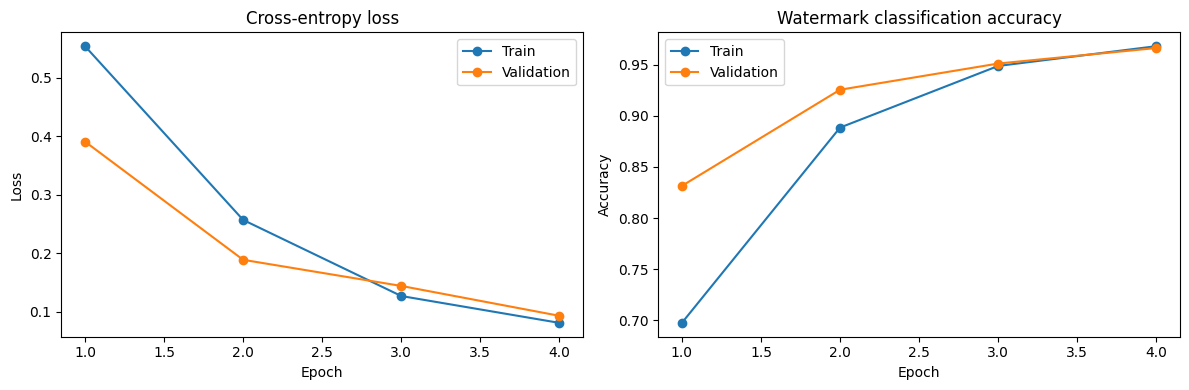

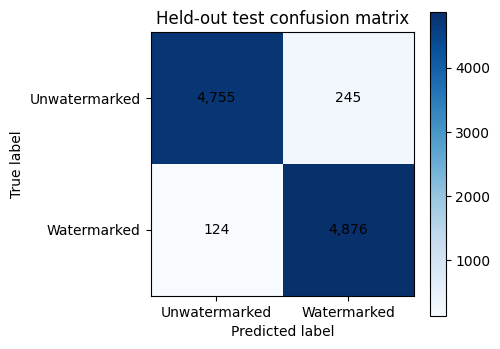

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(history["epoch"], history["train_loss"], marker="o", label="Train")
axs[0].plot(history["epoch"], history["val_loss"], marker="o", label="Validation")
axs[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axs[0].legend()

axs[1].plot(history["epoch"], history["train_accuracy"], marker="o", label="Train")
axs[1].plot(history["epoch"], history["val_accuracy"], marker="o", label="Validation")
axs[1].set(title="Watermark classification accuracy", xlabel="Epoch", ylabel="Accuracy")
axs[1].legend()
plt.tight_layout()
plt.show()

cm = np.array([
    [int(((test_results["targets"] == 0) & (test_results["preds"] == 0)).sum()),
     int(((test_results["targets"] == 0) & (test_results["preds"] == 1)).sum())],
    [int(((test_results["targets"] == 1) & (test_results["preds"] == 0)).sum()),
     int(((test_results["targets"] == 1) & (test_results["preds"] == 1)).sum())],
])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="black")
ax.set_xticks([0, 1], labels=["Unwatermarked", "Watermarked"])
ax.set_yticks([0, 1], labels=["Unwatermarked", "Watermarked"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Held-out test confusion matrix")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [13]:
SAVE_CHECKPOINT = True   # Change to True if you want to write the checkpoint to disk
CHECKPOINT_PATH = Path("resnet50_watermark_baseline.pt")
if SAVE_CHECKPOINT:
    torch.save({
        "model_state_dict": model.state_dict(),
        "watermark_pattern": watermark_pattern.cpu(),
        "watermark_strength": WATERMARK_STRENGTH,
        "image_size": IMAGE_SIZE,
        "imagenet_mean": IMAGENET_MEAN,
        "imagenet_std": IMAGENET_STD,
        "seed": SEED,
        "history": history.to_dict(orient="records"),
        "test_metrics": detection_metrics(test_results, "Test"),
    }, CHECKPOINT_PATH)
    print("Saved:", CHECKPOINT_PATH.resolve())
else:
    print("Checkpoint saving disabled. Set SAVE_CHECKPOINT=True to enable.")

Saved: C:\Users\TangyKiwi\Desktop\UCSD\DSC-261\resnet50_watermark_baseline.pt
